# BÀI TẬP TUẦN 10 — BOOTSTRAP VÀ MỞ ĐẦU VỀ KIỂM ĐỊNH GIẢ THUYẾT (MAT1052)
**Bài làm:** Bài 18


In [1]:
import numpy as np
import matplotlib.pyplot as plt


---
## Bài 18
**Đề bài:** Một phòng thí nghiệm kiểm tra tuổi thọ 20 viên pin (giờ), được chọn ngẫu nhiên và giả sử độc lập trong cùng điều kiện thử nghiệm:
$$380, 401, 415, 390, 428, 437, 395, 410, 422, 399, 405, 432, 418, 408, 394, 446, 413, 427, 402, 419.$$
Dùng Python (`numpy`) để lấy mẫu lại bootstrap có hoàn lại đúng 20 quan sát cho mỗi lần, với $B = 10\,000$ và bộ sinh số ngẫu nhiên `np.random.default_rng(1052)`. Chỉ sử dụng 20 số liệu đã cho.
- **Đơn vị quan sát:** Một viên pin được kiểm tra ($n = 20$).
- **Tham số cần nghiên cứu:** Tuổi thọ trung bình tổng thể $\mu$ và tuổi thọ trung vị tổng thể $M$ (giờ) của các viên pin cùng loại.
- **Giả định xác suất:** 20 viên pin được chọn ngẫu nhiên, độc lập và cùng phân phối (i.i.d.) từ tổng thể.


In [2]:
x = np.array([380, 401, 415, 390, 428, 437, 395, 410, 422, 399,
              405, 432, 418, 408, 394, 446, 413, 427, 402, 419])
n = len(x)

# a. Tính trung bình mẫu, trung vị mẫu và độ lệch chuẩn mẫu (ddof=1)
x_bar = x.mean()
med = np.median(x)
s = x.std(ddof=1)

# b. Lấy mẫu lại bootstrap có hoàn lại (B = 10 000, cỡ mẫu n = 20)
B = 10_000
rng = np.random.default_rng(1052)
mau_boot = rng.choice(x, size=(B, n), replace=True)

# Thống kê bootstrap cho trung bình và trung vị
tb_boot = mau_boot.mean(axis=1)
tv_boot = np.median(mau_boot, axis=1)

# Sai số chuẩn bootstrap và khoảng tin cậy 95% theo phân vị (0.025 và 0.975)
se_tb = tb_boot.std(ddof=1)
ci_tb = np.quantile(tb_boot, [0.025, 0.975])

se_tv = tv_boot.std(ddof=1)
ci_tv = np.quantile(tv_boot, [0.025, 0.975])

print(f"a) Trung bình mẫu x̄ = {x_bar:.4f} giờ")
print(f"   Trung vị mẫu m   = {med:.4f} giờ")
print(f"   Độ lệch chuẩn s  = {s:.4f} giờ\n")
print(f"b) Bootstrap cho TRUNG BÌNH (B = 10 000):")
print(f"   Tâm (trung bình các giá trị bootstrap) = {tb_boot.mean():.4f} giờ")
print(f"   Sai số chuẩn SE_boot                   = {se_tb:.4f} giờ")
print(f"   Khoảng tin cậy 95% theo phân vị        = [{ci_tb[0]:.4f}, {ci_tb[1]:.4f}] giờ\n")
print(f"   Bootstrap cho TRUNG VỊ (B = 10 000):")
print(f"   Tâm (trung bình các giá trị bootstrap) = {tv_boot.mean():.4f} giờ")
print(f"   Sai số chuẩn SE_boot                   = {se_tv:.4f} giờ")
print(f"   Khoảng tin cậy 95% theo phân vị        = [{ci_tv[0]:.4f}, {ci_tv[1]:.4f}] giờ")


a) Trung bình mẫu x̄ = 412.0500 giờ
   Trung vị mẫu m   = 411.5000 giờ
   Độ lệch chuẩn s  = 16.9161 giờ

b) Bootstrap cho TRUNG BÌNH (B = 10 000):
   Tâm (trung bình các giá trị bootstrap) = 411.9974 giờ
   Sai số chuẩn SE_boot                   = 3.6813 giờ
   Khoảng tin cậy 95% theo phân vị        = [404.9000, 419.3500] giờ

   Bootstrap cho TRUNG VỊ (B = 10 000):
   Tâm (trung bình các giá trị bootstrap) = 411.3578 giờ
   Sai số chuẩn SE_boot                   = 5.1551 giờ
   Khoảng tin cậy 95% theo phân vị        = [401.5000, 420.5000] giờ


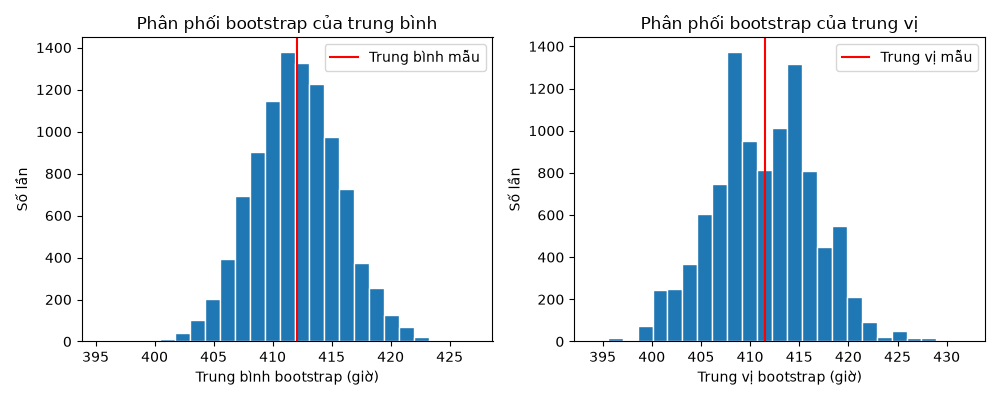

In [3]:
# Minh họa hai phân phối bootstrap để đối chiếu ở câu c
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].hist(tb_boot, bins=25, edgecolor="white")
axes[0].axvline(x_bar, color="red", label="Trung bình mẫu")
axes[0].set_title("Phân phối bootstrap của trung bình")
axes[0].set_xlabel("Trung bình bootstrap (giờ)")
axes[0].set_ylabel("Số lần")
axes[0].legend()

axes[1].hist(tv_boot, bins=25, edgecolor="white")
axes[1].axvline(med, color="red", label="Trung vị mẫu")
axes[1].set_title("Phân phối bootstrap của trung vị")
axes[1].set_xlabel("Trung vị bootstrap (giờ)")
axes[1].set_ylabel("Số lần")
axes[1].legend()

plt.tight_layout()
plt.show()


### Giải thích cách làm và trả lời chi tiết

**Cách thực hiện mô phỏng:**
- Từ mẫu gốc cỡ $n = 20$, dùng `rng.choice(x, size=(10_000, 20), replace=True)` với `default_rng(1052)` để rút ngẫu nhiên **có hoàn lại** $B = 10\,000$ mẫu bootstrap, mỗi mẫu gồm đúng 20 quan sát.
- Trên mỗi mẫu bootstrap (từng hàng), tính trung bình mẫu $\bar{x}^*$ và trung vị mẫu $m^*$. Sai số chuẩn $\widehat{SE}_{\text{boot}}$ là độ lệch chuẩn mẫu (`ddof=1`) của $10\,000$ giá trị thống kê bootstrap vừa thu được; khoảng tin cậy 95% theo phương pháp phân vị được lấy từ hai phân vị mức $0.025$ và $0.975$.

---
- **a. Các thống kê của mẫu gốc ($n = 20$):**
  - Trung bình mẫu: $\bar{x} = 412.05$ giờ.
  - Trung vị mẫu (trung bình cộng của số hạng thứ 10 là $410$ và thứ 11 là $413$ sau khi sắp xếp): $m = 411.50$ giờ.
  - Độ lệch chuẩn mẫu (mẫu số $n - 1 = 19$): $s \approx 16.9161$ giờ.

- **b. Kết quả $B = 10\,000$ mẫu bootstrap:**
  - **Đối với trung bình:** $\widehat{SE}_{\text{boot}}(\bar{X}^*) \approx 3.6813$ giờ (khá sát với $s/\sqrt{n} \approx 3.7826$ giờ); khoảng tin cậy bootstrap 95% theo phân vị là **$[404.90;\, 419.35]$ giờ** (độ rộng $14.45$ giờ).
  - **Đối với trung vị:** $\widehat{SE}_{\text{boot}}(M^*) \approx 5.1551$ giờ; khoảng tin cậy bootstrap 95% theo phân vị là **$[401.50;\, 420.50]$ giờ** (độ rộng $19.00$ giờ).

- **c. So sánh hai phân phối bootstrap và cách tính phân vị:**
  - **Về tâm:** Tâm của cả hai phân phối đều bám sát giá trị thống kê trên mẫu gốc và khá gần nhau: trung bình của các trung bình bootstrap là $\approx 411.9974$ giờ ($\approx \bar{x} = 412.05$), trung bình của các trung vị bootstrap là $\approx 411.3578$ giờ (trung vị là $411.50 = m$).
  - **Về độ phân tán:** Phân phối bootstrap của trung vị phân tán lớn hơn rõ rệt so với trung bình ($\widehat{SE}_{\text{boot}} \approx 5.1551 > 3.6813$ giờ) và cho khoảng tin cậy 95% rộng hơn ($19.00$ giờ so với $14.45$ giờ), vì trung vị chỉ dựa vào hai giá trị ở giữa thay vì sử dụng toàn bộ 20 giá trị như trung bình.
  - **Về hình dạng:** Phân phối bootstrap của **trung bình** mịn, liên tục hơn (có 443 giá trị khác nhau), đối xứng và có dạng hình chuông xấp xỉ phân phối chuẩn (nhờ Định lý giới hạn trung tâm). Ngược lại, phân phối bootstrap của **trung vị** rời rạc, gấp khúc và có nhiều đỉnh/khoảng trống (chỉ nhận 57 giá trị khác nhau là trung bình cộng của các cặp giá trị lấy từ mẫu gốc).
  - **Cách tính phân vị đã dùng:** Sử dụng hàm `np.quantile(..., [0.025, 0.975])` với phương pháp mặc định `method='linear'` của NumPy (nội suy tuyến tính tại chỉ số thực $p(B - 1)$ trên dãy đã sắp xếp). Do sự ngẫu nhiên của mô phỏng hữu hạn và tính rời rạc (đặc biệt ở trung vị), kết quả số có thể thay đổi đôi chút nếu đổi hạt giống/bộ sinh số ngẫu nhiên hoặc đổi định nghĩa phân vị.

- **d. Khi 20 viên pin đến từ 2 lô (mỗi lô 10 viên) và các viên pin trong cùng lô phụ thuộc nhau:**
  - **Thao tác phải xem xét lại:** Thao tác lấy mẫu lại **từng viên pin riêng lẻ** (20 quan sát độc lập có hoàn lại từ 20 viên pin) không còn hợp lệ.
  - **Giải thích:** Khi các viên pin trong cùng một lô phụ thuộc nhau, giả định 20 quan sát độc lập bị vi phạm; **đơn vị lấy mẫu độc lập thực sự lúc này là từng lô pin (cụm/cluster)** chứ không phải từng viên pin, nên cỡ mẫu độc lập thực chất chỉ là $2$ lô (không phải $20$). Nếu vẫn rút lại từng viên pin riêng lẻ, ta đã phá vỡ cấu trúc tương quan trong cùng lô và đánh giá thấp sai số chuẩn. Khi dữ liệu theo cụm, thao tác bootstrap đúng là phải lấy mẫu lại theo cụm (rút lại các lô có hoàn lại); tuy nhiên với chỉ 2 lô độc lập thì lượng thông tin quá ít để bootstrap ước lượng đáng tin cậy cho cả tổng thể các lô pin.
